# Detecting Persistent Product Substitution and Potential Cannibalization: A project plan using change-point analysis of household grocery purchases
#### By Mattheus Marcus Contreras and Nikkei Jane Espina


### Executive Summary

Retailers can observe that sales changed, but not immediately whether the change reflects genuine category growth, temporary promotion response, or households switching between competing brands. This project develops an interpretable framework that first detects structural changes in household purchase behavior, then identifies substitution patterns, and finally measures whether the new behavior persists.

### Research Questions

1. At what points do households exhibit statistically meaningful changes in purchasing patterns within selected product categories?
2. After a detected change point, do households shift purchases from one competing product or brand to another?
3. Are gains in one product accompanied by losses in a competing product without substantial category growth?
4. Are detected shifts temporary, or do households maintain the new purchasing pattern?
5. Are temporary and persistent shifts associated with differences in price or promotional exposure?


### Conceptual Framework

##### Stage 1: Detect
Identify when a household’s brand or product allocation changes significantly.
##### Stage 2: Classify
Determine whether the event reflects substitution, category expansion or contraction, cessation, or temporary switching.
##### Stage 3: Evaluate potential cannibalization
Test whether the gaining product’s increase corresponds with a competing product’s decline while category demand remains approximately stable.
##### Stage 4: Measure persistence
Determine whether the household maintains the post-change state or reverts to its previous behavior.
Interpretation rule  Use “consistent with potential cannibalization,” not “Product B caused Product A’s decline,” unless a causal design is added.


### Operational Definitions

#### Change point
A week or purchase occasion at which a household’s purchasing pattern moves from one relatively stable state to another. Example: Brand A receives 80% of category purchases before Week 13 and 25% afterward, while Brand B becomes dominant.

#### Substitution
- Product or Brand A share/quantity declines.
- Product or Brand B share/quantity increases.
- A and B compete within the same category.
- Total category purchasing does not increase proportionately.
Initial rule for testing: A decreases by at least 20 percentage points, B increases by at least 20 percentage points, and total category volume remains within ±20%. These thresholds must be tested through sensitivity analysis.

#### Potential cannibalization
A stronger business interpretation of substitution, used when gains and losses occur among direct competitors, category demand remains stable, the pattern repeats across households, and it is not merely a short promotional spike.

#### Persistence and reversion
Primary persistence rule: the new dominant brand is maintained for at least eight weeks and at least 60% of post-change category purchases follow the new pattern. A purchase-occasion version should require the next three to five category purchases to support the new state. Reversion occurs when allocation returns to within 10 percentage points of the pre-change state.


In [1]:
### Setup and Loading Data

import numpy as np
import pandas as pd
import sqlite3

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_style("whitegrid")

pd.set_option("display.max_columns", None)

transactions = pd.read_csv("data/transaction_data.csv")
products = pd.read_csv("data/product.csv")
households = pd.read_csv("data/hh_demographic.csv")
coupon = pd.read_csv("data/coupon.csv")
coupon_redempt = pd.read_csv("data/coupon_redempt.csv")
campaign_table = pd.read_csv("data/campaign_table.csv")
campaign_desc = pd.read_csv("data/campaign_desc.csv")

conn = sqlite3.connect(":memory:")

transactions.to_sql("transactions", conn, index=False, if_exists="replace")
products.to_sql("products", conn, index=False, if_exists="replace")
households.to_sql("household", conn, index=False, if_exists="replace")
coupon.to_sql("coupon", conn, index=False, if_exists="replace")
coupon_redempt.to_sql("coupon_redempt", conn, index=False, if_exists="replace")
campaign_table.to_sql("campaign_table", conn, index=False, if_exists="replace")
campaign_desc.to_sql("campaign_desc", conn, index=False, if_exists="replace")

print(transactions.shape)
print(products.shape)
print(households.shape)

### Transaction Table
print(transactions.info())
print(transactions.isnull().sum())
print(transactions.duplicated().sum())
print(transactions.describe())

### Product table
print(products.info())
print(products.isnull().sum())
print(products.duplicated().sum())

##Household table
print(households.info())
print(households.isnull().sum())
print(households.duplicated().sum())


(2595732, 12)
(92353, 7)
(801, 8)
<class 'pandas.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   BASKET_ID          int64  
 2   DAY                int64  
 3   PRODUCT_ID         int64  
 4   QUANTITY           int64  
 5   SALES_VALUE        float64
 6   STORE_ID           int64  
 7   RETAIL_DISC        float64
 8   TRANS_TIME         int64  
 9   WEEK_NO            int64  
 10  COUPON_DISC        float64
 11  COUPON_MATCH_DISC  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB
None
household_key        0
BASKET_ID            0
DAY                  0
PRODUCT_ID           0
QUANTITY             0
SALES_VALUE          0
STORE_ID             0
RETAIL_DISC          0
TRANS_TIME           0
WEEK_NO              0
COUPON_DISC          0
COUPON_MATCH_DISC    0
dtype: int64
0
       household_key     BASKET_ID           DAY    PRODUCT_ID      

# Building Master Data

#### Transaction Level Master Data

In [2]:
query = ''' 
SELECT t.*, p.manufacturer, p.department, p.brand, p.commodity_desc, p.sub_commodity_desc, p.curr_size_of_product,
h.age_desc,	h.marital_status_code, h.income_desc, h.homeowner_desc, h.hh_comp_desc, 
h.household_size_desc, h.kid_category_desc
FROM transactions t
LEFT JOIN products p
ON t.product_id = p.product_id
LEFT JOIN household h
ON t.household_key = h.household_key;
'''
df_transaction = pd.read_sql_query(query, conn)

df_transaction.head()

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT,AGE_DESC,MARITAL_STATUS_CODE,INCOME_DESC,HOMEOWNER_DESC,HH_COMP_DESC,HOUSEHOLD_SIZE_DESC,KID_CATEGORY_DESC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0,69,PRODUCE,Private,POTATOES,POTATOES RUSSET (BULK&BAG),5 LB,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0,2,PRODUCE,National,ONIONS,ONIONS SWEET (BULK&BAG),40 LB,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0,69,PRODUCE,Private,VEGETABLES - ALL OTHERS,CELERY,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0,2,PRODUCE,National,TROPICAL FRUIT,BANANAS,40 LB,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0,69,PRODUCE,Private,ORGANICS FRUIT & VEGETABLES,ORGANIC CARROTS,1 LB,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Coupon-Level Master Data

In [3]:
query = ''' 
SELECT
    c.coupon_upc,
    c.campaign,
    c.product_id,
    p.manufacturer,
    p.department,
    p.brand,
    p.commodity_desc,
    p.sub_commodity_desc,
    p.curr_size_of_product
FROM coupon c
LEFT JOIN products p
    ON c.product_id = p.product_id;
'''
df_coupon = pd.read_sql_query(query, conn)

df_coupon.head()

,COUPON_UPC,CAMPAIGN,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,10000089061,4,27160,69,GROCERY,Private,SHORTENING/OIL,VEGETABLE/SALAD OIL,48 OZ
1,10000089064,9,27754,69,GROCERY,Private,FRZN VEGETABLE/VEG DSH,FRZN BAGGED VEGETABLES - PLAIN,16 OZ
2,10000089073,12,28897,69,GROCERY,Private,EGGS,EGGS - X-LARGE,A D 1 DZ
3,51800009050,28,28919,236,GROCERY,National,REFRGRATD DOUGH PRODUCTS,REFRIGERATED COOKIES-CHUB,16.5 OZ
4,52100000076,25,28929,317,GROCERY,National,CHEESE,STRING CHEESE,AB 8 OZ


#### Coupon Redemption Master Data

In [4]:
query_coupon_redemption = '''
SELECT
    cr.household_key,
    cr.coupon_upc,
    cr.day AS redemption_day,
    c.campaign,
    c.product_id,
    p.manufacturer,
    p.department,
    p.brand,
    p.commodity_desc,
    p.sub_commodity_desc,
    p.curr_size_of_product
FROM coupon_redempt cr
LEFT JOIN coupon c
    ON cr.coupon_upc = c.coupon_upc
LEFT JOIN products p
    ON c.product_id = p.product_id;
'''

df_coupon_redemption = pd.read_sql_query(query_coupon_redemption,conn)

df_coupon_redemption.head()

,household_key,COUPON_UPC,redemption_day,CAMPAIGN,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,1,10000085364,421,8,28272,69,GROCERY,Private,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,1 QT
1,1,10000085364,421,8,28897,69,GROCERY,Private,EGGS,EGGS - X-LARGE,A D 1 DZ
2,1,10000085364,421,8,28966,69,GROCERY,Private,EGGS,EGGS - MEDIUM,ABD 1 DZ
3,1,10000085364,421,8,32387,69,GROCERY,Private,MILK BY-PRODUCTS,COTTAGE CHEESE,24 OZ
4,1,10000085364,421,8,32553,69,GROCERY,Private,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,


### Descriptive Profiles of the Master Tables

In [14]:
level_transaction = {
    "household_key": "Nominal (identifier)",
    "BASKET_ID": "Nominal (identifier)",
    "DAY": "Interval",
    "PRODUCT_ID": "Nominal (identifier)",
    "QUANTITY": "Ratio",
    "SALES_VALUE": "Ratio",
    "STORE_ID": "Nominal (identifier)",
    "RETAIL_DISC": "Ratio",
    "TRANS_TIME": "Interval",
    "WEEK_NO": "Interval",
    "COUPON_DISC": "Ratio",
    "COUPON_MATCH_DISC": "Ratio",
    "MANUFACTURER": "Nominal (identifier)",
    "DEPARTMENT": "Nominal",
    "BRAND": "Nominal",
    "COMMODITY_DESC": "Nominal",
    "SUB_COMMODITY_DESC": "Nominal",
    "CURR_SIZE_OF_PRODUCT": "Nominal",
    "AGE_DESC": "Ordinal",
    "MARITAL_STATUS_CODE": "Nominal",
    "INCOME_DESC": "Ordinal",
    "HOMEOWNER_DESC": "Nominal",
    "HH_COMP_DESC": "Nominal",
    "HOUSEHOLD_SIZE_DESC": "Ordinal",
    "KID_CATEGORY_DESC": "Ordinal"
}

schema_transaction = pd.DataFrame({
    "dtype": df_transaction.dtypes.astype(str),
    "level_of_measurement": pd.Series(level_transaction),
    "n_unique": df_transaction.nunique(),
    "n_missing": df_transaction.isna().sum(),
    "pct_missing": (df_transaction.isna().mean() * 100).round(2)
})

schema_transaction

,dtype,level_of_measurement,n_unique,n_missing,pct_missing
household_key,int64,Nominal (identifier),2500,0,0.00
BASKET_ID,int64,Nominal (identifier),276484,0,0.00
DAY,int64,Interval,711,0,0.00
PRODUCT_ID,int64,Nominal (identifier),92339,0,0.00
QUANTITY,int64,Ratio,11746,0,0.00
SALES_VALUE,float64,Ratio,5502,0,0.00
STORE_ID,int64,Nominal (identifier),582,0,0.00
RETAIL_DISC,float64,Ratio,2414,0,0.00
TRANS_TIME,int64,Interval,1440,0,0.00
WEEK_NO,int64,Interval,102,0,0.00


In [6]:
level_coupon = {
    "COUPON_UPC": "Nominal (identifier)",
    "CAMPAIGN": "Nominal (identifier)",
    "PRODUCT_ID": "Nominal (identifier)",
    "MANUFACTURER": "Nominal (identifier)",
    "DEPARTMENT": "Nominal",
    "BRAND": "Nominal",
    "COMMODITY_DESC": "Nominal",
    "SUB_COMMODITY_DESC": "Nominal",
    "CURR_SIZE_OF_PRODUCT": "Nominal"
}

schema_coupon = pd.DataFrame({
    "dtype": df_coupon.dtypes.astype(str),
    "level_of_measurement": pd.Series(level_coupon),
    "n_unique": df_coupon.nunique(),
    "n_missing": df_coupon.isna().sum(),
    "pct_missing": (df_coupon.isna().mean() * 100).round(2)
})

schema_coupon

,dtype,level_of_measurement,n_unique,n_missing,pct_missing
COUPON_UPC,int64,Nominal (identifier),1135,0,0.0
CAMPAIGN,int64,Nominal (identifier),30,0,0.0
PRODUCT_ID,int64,Nominal (identifier),44133,0,0.0
MANUFACTURER,int64,Nominal (identifier),2967,0,0.0
DEPARTMENT,str,Nominal,29,0,0.0
BRAND,str,Nominal,2,0,0.0
COMMODITY_DESC,str,Nominal,266,0,0.0
SUB_COMMODITY_DESC,str,Nominal,1363,0,0.0
CURR_SIZE_OF_PRODUCT,str,Nominal,2279,0,0.0


In [7]:
level_coupon_redemption = {
    "household_key": "Nominal (identifier)",
    "COUPON_UPC": "Nominal (identifier)",
    "redemption_day": "Interval",
    "CAMPAIGN": "Nominal (identifier)",
    "PRODUCT_ID": "Nominal (identifier)",
    "MANUFACTURER": "Nominal (identifier)",
    "DEPARTMENT": "Nominal",
    "BRAND": "Nominal",
    "COMMODITY_DESC": "Nominal",
    "SUB_COMMODITY_DESC": "Nominal",
    "CURR_SIZE_OF_PRODUCT": "Nominal"
}

schema_coupon_redemption = pd.DataFrame({
    "dtype": df_coupon_redemption.dtypes.astype(str),
    "level_of_measurement": pd.Series(level_coupon_redemption),
    "n_unique": df_coupon_redemption.nunique(),
    "n_missing": df_coupon_redemption.isna().sum(),
    "pct_missing": (
        df_coupon_redemption.isna().mean() * 100
    ).round(2)
})

schema_coupon_redemption

,dtype,level_of_measurement,n_unique,n_missing,pct_missing
household_key,int64,Nominal (identifier),434,0,0.0
COUPON_UPC,int64,Nominal (identifier),556,0,0.0
redemption_day,int64,Interval,328,0,0.0
CAMPAIGN,int64,Nominal (identifier),30,0,0.0
PRODUCT_ID,int64,Nominal (identifier),42218,0,0.0
MANUFACTURER,int64,Nominal (identifier),2906,0,0.0
DEPARTMENT,str,Nominal,28,0,0.0
BRAND,str,Nominal,2,0,0.0
COMMODITY_DESC,str,Nominal,254,0,0.0
SUB_COMMODITY_DESC,str,Nominal,1268,0,0.0


##### Measures of Central Tendency

note to be deleted:

Let's say a retailer sees sales growing for certain products while competing products within the same category are declining. We want to know whether this reflects genuine category growth or product cannibalization, where gains for one product come at the expense of another. The question is: what does a typical purchase look like within each competitive product category, and are a small number of unusually large purchases distorting the apparent demand?

In [8]:
### question that needs to be answered here: 
# Within each product category/competitive set, what is the typical transaction sales value?
# Do unusually large purchases distort our view of typical demand within a competitive category?
central_tendency = (
    df_transaction
    .groupby("SUB_COMMODITY_DESC", observed=True)
    .agg(
        sales_mean=("SALES_VALUE", "mean"),
        sales_median=("SALES_VALUE", "median"),
        quantity_mean=("QUANTITY", "mean"),
        quantity_median=("QUANTITY", "median"),
        n=("SALES_VALUE", "count")
    )
    .round(2)
)

# Mean-to-median ratios
central_tendency["sales_mean_to_median_ratio"] = (
    central_tendency["sales_mean"] /
    central_tendency["sales_median"]
).round(2)

central_tendency["quantity_mean_to_median_ratio"] = (
    central_tendency["quantity_mean"] /
    central_tendency["quantity_median"]
).round(2)

# Display categories with sufficient observations
central_tendency_display = (
    central_tendency
    .query("n >= 100")
    .sort_values("n", ascending=False)
    .head(10)
)

central_tendency_display

# note to be deleted:
# Showing the 10 groups with the largest number of observations provides a concise view 
# of the most frequently purchased product groups, where the mean and median are based on 
# comparatively more data. The remaining sub-commodities should still be retained in the dataset 
# and used in subsequent analysis; the 10-row table is simply a descriptive summary for presentation.

,sales_mean,sales_median,quantity_mean,quantity_median,n,sales_mean_to_median_ratio,quantity_mean_to_median_ratio
SUB_COMMODITY_DESC,,,,,,,
FLUID MILK WHITE ONLY,2.46,2.32,1.39,1.0,65764,1.06,1.39
SOFT DRINKS 12/18&15PK CAN CAR,4.02,3.33,1.40,1.0,39352,1.21,1.40
YOGURT NOT MULTI-PACKS,1.03,0.78,1.77,1.0,37440,1.32,1.77
SFT DRNK 2 LITER BTL CARB INCL,1.44,1.18,1.46,1.0,37273,1.22,1.46
BANANAS,1.00,0.93,1.04,1.0,30436,1.08,1.04
MAINSTREAM WHITE BREAD,1.62,1.50,1.27,1.0,27392,1.08,1.27
SHREDDED CHEESE,2.47,1.78,1.29,1.0,27343,1.39,1.29
CANDY BARS (SINGLES)(INCLUDING,0.68,0.59,1.78,1.0,26070,1.15,1.78
GASOLINE-REG UNLEADED,25.40,24.12,10308.95,10267.0,24962,1.05,1.00


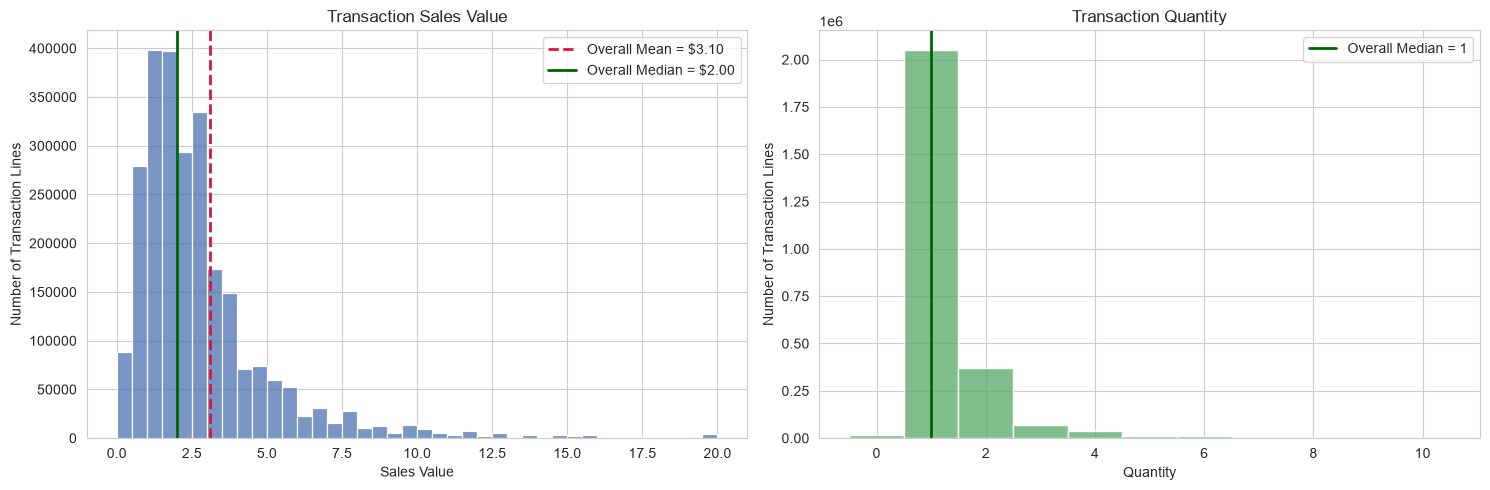

Sales: mean=3.10, median=2.00, skew=15.91
Quantity: mean=100.43, median=1.00, skew=13.64


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sales = df_transaction["SALES_VALUE"].dropna()
quantity = df_transaction["QUANTITY"].dropna()

sales_mean = sales.mean()
sales_median = sales.median()
sales_skew = stats.skew(sales)

quantity_mean = quantity.mean()
quantity_median = quantity.median()
quantity_skew = stats.skew(quantity)

sales_p99 = sales.quantile(0.99)
quantity_p99 = quantity.quantile(0.99)

# SALES VALUE
sns.histplot(sales[sales <= sales_p99], bins=40, color="#4C72B0", ax=axes[0])
axes[0].axvline(
    sales_mean,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Overall Mean = ${sales_mean:.2f}"
)

axes[0].axvline(
    sales_median,
    color="darkgreen",
    linewidth=2,
    label=f"Overall Median = ${sales_median:.2f}"
)

axes[0].set_title("Transaction Sales Value")
axes[0].set_xlabel("Sales Value")
axes[0].set_ylabel("Number of Transaction Lines")
axes[0].legend()


# QUANTITY
sns.histplot(
    quantity[quantity <= quantity_p99],
    discrete=True,
    color="#55A868",
    ax=axes[1]
)

# Median only, because full-data mean may be outside plotted range
axes[1].axvline(
    quantity_median,
    color="darkgreen",
    linewidth=2,
    label=f"Overall Median = {quantity_median:.0f}"
)

axes[1].set_title("Transaction Quantity")
axes[1].set_xlabel("Quantity")
axes[1].set_ylabel("Number of Transaction Lines")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Sales: mean={sales_mean:.2f}, median={sales_median:.2f}, skew={sales_skew:.2f}")
print(f"Quantity: mean={quantity_mean:.2f}, median={quantity_median:.2f}, skew={quantity_skew:.2f}")

In [10]:
print("\nModal household characteristics:")
print("Age group:",df_transaction["AGE_DESC"].mode()[0])
print("Income group:",df_transaction["INCOME_DESC"].mode()[0])
print("Household size:",df_transaction["HOUSEHOLD_SIZE_DESC"].mode()[0])
print("Kids category:",df_transaction["KID_CATEGORY_DESC"].mode()[0])


Modal household characteristics:
Age group: 45-54
Income group: 50-74K
Household size: 2
Kids category: None/Unknown


#### Measures of Spread

note to be deleted:
Two competing product groups may have similar average sales or purchase quantities, but very different levels of variability. Before interpreting changes in demand as evidence of cannibalization, it is necessary to establish how much sales value and purchase volume normally fluctuate within each product group. A decline that appears substantial in a stable category may simply represent ordinary variation in a highly volatile category.

In [11]:
spread_by_subcommodity = (
    df_transaction
    .groupby("SUB_COMMODITY_DESC", observed=True)
    .agg(
        sales_mean=("SALES_VALUE", "mean"),
        sales_range=("SALES_VALUE", lambda s: s.max() - s.min()),
        sales_variance=("SALES_VALUE", lambda s: s.var(ddof=1)),
        sales_std=("SALES_VALUE", "std"),
        sales_iqr=("SALES_VALUE",
                   lambda s: np.percentile(s.dropna(), 75) -
                             np.percentile(s.dropna(), 25)),

        quantity_mean=("QUANTITY", "mean"),
        quantity_range=("QUANTITY", lambda s: s.max() - s.min()),
        quantity_variance=("QUANTITY", lambda s: s.var(ddof=1)),
        quantity_std=("QUANTITY", "std"),
        quantity_iqr=("QUANTITY",
                      lambda s: np.percentile(s.dropna(), 75) -
                                np.percentile(s.dropna(), 25)),
        n=("SALES_VALUE", "count")).round(2))
spread_display = (spread_by_subcommodity.query("n >= 100").sort_values("n", ascending=False).head(10)
)

spread_display

,sales_mean,sales_range,sales_variance,sales_std,sales_iqr,quantity_mean,quantity_range,quantity_variance,quantity_std,quantity_iqr,n
SUB_COMMODITY_DESC,,,,,,,,,,,
FLUID MILK WHITE ONLY,2.46,31.08,1.93,1.39,1.00,1.39,28,0.94,0.97,0.0,65764
SOFT DRINKS 12/18&15PK CAN CAR,4.02,176.03,11.34,3.37,2.09,1.40,40,1.36,1.16,0.0,39352
YOGURT NOT MULTI-PACKS,1.03,12.00,0.75,0.86,0.70,1.77,22,1.75,1.32,1.0,37440
SFT DRNK 2 LITER BTL CARB INCL,1.44,78.79,1.99,1.41,0.90,1.46,50,1.60,1.26,1.0,37273
BANANAS,1.00,13.69,0.31,0.56,0.57,1.04,9,0.05,0.23,0.0,30436
MAINSTREAM WHITE BREAD,1.62,43.51,0.78,0.88,0.98,1.27,19,0.36,0.60,0.0,27392
SHREDDED CHEESE,2.47,32.89,2.29,1.51,1.40,1.29,13,0.42,0.65,0.0,27343
CANDY BARS (SINGLES)(INCLUDING,0.68,43.01,0.67,0.82,0.65,1.78,74,4.01,2.00,1.0,26070
GASOLINE-REG UNLEADED,25.40,249.97,161.58,12.71,16.73,10308.95,89637,33121718.41,5755.15,7443.0,24962


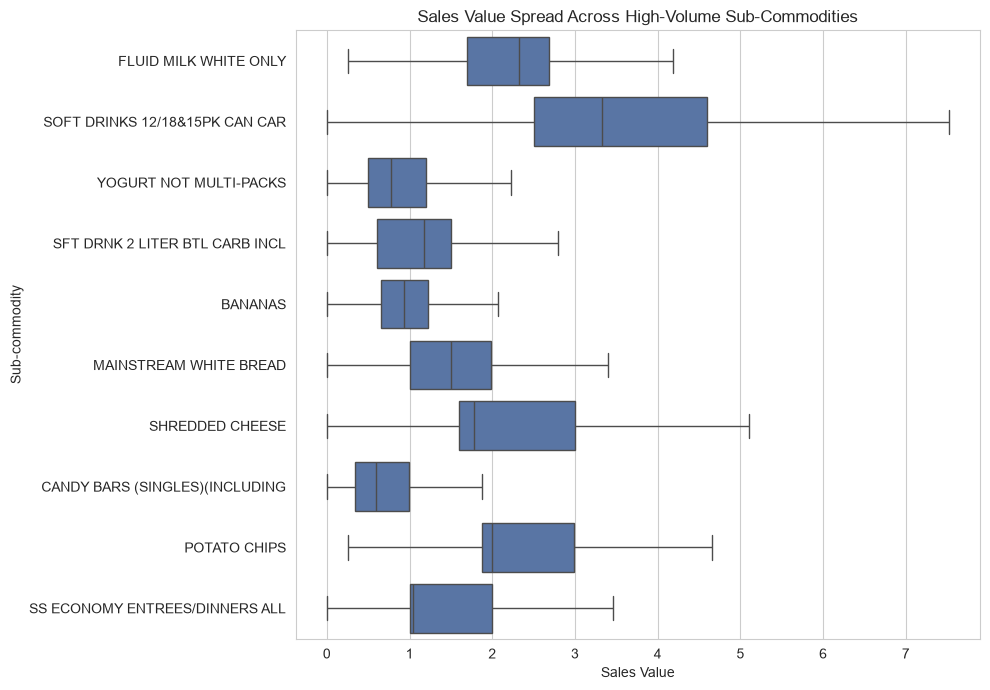

In [12]:
top_10_subcommodities = (
    central_tendency
    .drop(index="GASOLINE-REG UNLEADED", errors="ignore")
    .query("n >= 100")
    .sort_values("n", ascending=False)
    .head(10)
    .index
)

plot_data = df_transaction[
    df_transaction["SUB_COMMODITY_DESC"].isin(top_10_subcommodities)
].copy()

fig, ax = plt.subplots(figsize=(10, 7))

sns.boxplot(
    data=plot_data,
    y="SUB_COMMODITY_DESC",
    x="SALES_VALUE",
    order=top_10_subcommodities,
    color="#4C72B0",
    showfliers=False,
    ax=ax
)

ax.set_title("Sales Value Spread Across High-Volume Sub-Commodities")
ax.set_xlabel("Sales Value")
ax.set_ylabel("Sub-commodity")

plt.tight_layout()
plt.show()


In [15]:
# Inject realistic data-quality issues into a COPY of the clean transaction master table.
# The original df_transaction remains unchanged.
# Issues demonstrated: duplicates, invalid negatives, missing categorical data,
# and missing product information.

messy_transaction_df = df_transaction.copy()

# 1. Duplicate transaction rows
dup_rows = messy_transaction_df.sample(6, random_state=1)
messy_transaction_df = pd.concat(
    [messy_transaction_df, dup_rows],
    ignore_index=True
)

# 2. Invalid negative sales values
bad_sales_idx = messy_transaction_df.sample(4, random_state=2).index
messy_transaction_df.loc[bad_sales_idx, "SALES_VALUE"] = -abs(
    messy_transaction_df.loc[bad_sales_idx, "SALES_VALUE"]
)

# 3. Invalid negative quantity
bad_quantity_idx = messy_transaction_df.sample(3, random_state=3).index
messy_transaction_df.loc[bad_quantity_idx, "QUANTITY"] = -abs(
    messy_transaction_df.loc[bad_quantity_idx, "QUANTITY"]
)

# 4. Missing commodity descriptions
missing_commodity_idx = messy_transaction_df.sample(15, random_state=4).index
messy_transaction_df.loc[
    missing_commodity_idx, "COMMODITY_DESC"
] = None

# 5. Missing household income information
missing_income_idx = messy_transaction_df.sample(9, random_state=5).index
messy_transaction_df.loc[
    missing_income_idx, "INCOME_DESC"
] = None

print(f"Clean transaction shape: {df_transaction.shape}")
print(f"Messy transaction shape: {messy_transaction_df.shape}")

Clean transaction shape: (2595732, 25)
Messy transaction shape: (2595738, 25)


In [16]:
# Inject realistic data-quality issues into a COPY of the clean coupon master table.
# Issues demonstrated: duplicates, missing product classifications,
# missing manufacturer information, and invalid campaign identifiers.

messy_coupon_df = df_coupon.copy()

# 1. Duplicate coupon rows
dup_rows = messy_coupon_df.sample(6, random_state=11)
messy_coupon_df = pd.concat(
    [messy_coupon_df, dup_rows],
    ignore_index=True
)

# 2. Missing commodity descriptions
missing_commodity_idx = messy_coupon_df.sample(10, random_state=12).index
messy_coupon_df.loc[
    missing_commodity_idx, "COMMODITY_DESC"
] = None

# 3. Missing sub-commodity descriptions
missing_subcommodity_idx = messy_coupon_df.sample(8, random_state=13).index
messy_coupon_df.loc[
    missing_subcommodity_idx, "SUB_COMMODITY_DESC"
] = None

# 4. Missing manufacturer information
missing_manufacturer_idx = messy_coupon_df.sample(5, random_state=14).index
messy_coupon_df.loc[
    missing_manufacturer_idx, "MANUFACTURER"
] = np.nan

# 5. Invalid campaign identifier
bad_campaign_idx = messy_coupon_df.sample(3, random_state=15).index
messy_coupon_df.loc[
    bad_campaign_idx, "CAMPAIGN"
] = -1

print(f"Clean coupon shape: {df_coupon.shape}")
print(f"Messy coupon shape: {messy_coupon_df.shape}")

Clean coupon shape: (124548, 9)
Messy coupon shape: (124554, 9)


In [17]:
# Inject realistic data-quality issues into a COPY of the clean coupon-redemption
# master table.
# Issues demonstrated: duplicate redemptions, invalid dates,
# missing product classifications, and missing household identifiers.

messy_redemption_df = df_coupon_redemption.copy()

# 1. Duplicate redemption records
dup_rows = messy_redemption_df.sample(6, random_state=21)
messy_redemption_df = pd.concat(
    [messy_redemption_df, dup_rows],
    ignore_index=True
)

# 2. Invalid negative redemption day
bad_day_idx = messy_redemption_df.sample(4, random_state=22).index
messy_redemption_df.loc[
    bad_day_idx, "redemption_day"
] = -1

# 3. Missing household identifiers
missing_household_idx = messy_redemption_df.sample(5, random_state=23).index
messy_redemption_df.loc[
    missing_household_idx, "household_key"
] = np.nan

# 4. Missing commodity descriptions
missing_commodity_idx = messy_redemption_df.sample(10, random_state=24).index
messy_redemption_df.loc[
    missing_commodity_idx, "COMMODITY_DESC"
] = None

# 5. Missing product identifiers
missing_product_idx = messy_redemption_df.sample(5, random_state=25).index
messy_redemption_df.loc[
    missing_product_idx, "PRODUCT_ID"
] = np.nan

print(f"Clean coupon-redemption shape: {df_coupon_redemption.shape}")
print(f"Messy coupon-redemption shape: {messy_redemption_df.shape}")

Clean coupon-redemption shape: (2318441, 11)
Messy coupon-redemption shape: (2318447, 11)


In [ ]:
def profile_dataset(df):
    report = {}

    # dataset information
    report["n_rows"] = len(df)
    report["n_duplicate_rows"] = int(df.duplicated().sum())

    # Missing values
    missing = df.isnull().sum()

    report["missing_by_column"] = missing[missing > 0]

    # Invalid / out-of-range values
    out_of_range = {}

    # Transaction-level checks
    if "SALES_VALUE" in df.columns:
        mask = df["SALES_VALUE"] < 0
        out_of_range["SALES_VALUE (negative)"] = int(mask.sum())

    if "QUANTITY" in df.columns:
        mask = df["QUANTITY"] < 0
        out_of_range["QUANTITY (negative)"] = int(mask.sum())

    # Coupon-level check
    if "CAMPAIGN" in df.columns:
        mask = df["CAMPAIGN"] < 0
        out_of_range["CAMPAIGN (negative)"] = int(mask.sum())

    # Coupon-redemption-level check
    if "redemption_day" in df.columns:
        mask = df["redemption_day"] < 0
        out_of_range["redemption_day (negative)"] = int(mask.sum())

    report["out_of_range_counts"] = out_of_range

    # Statistical outliers
    if "SALES_VALUE" in df.columns:

        q1, q3 = df["SALES_VALUE"].quantile([0.25, 0.75])
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        report["sales_value_outlier_count"] = int(
            (
                (df["SALES_VALUE"] < lower)
                | (df["SALES_VALUE"] > upper)
            ).sum()
        )

    return report

transaction_profile = profile_dataset(messy_transaction_df)
coupon_profile = profile_dataset(messy_coupon_df)
redemption_profile = profile_dataset(messy_redemption_df)

def print_profile(name, profile):

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(f"Rows: {profile['n_rows']}")
    print(f"Exact duplicate rows: {profile['n_duplicate_rows']}")

    print("\nMissing values by column:")

    if len(profile["missing_by_column"]) > 0:
        print(profile["missing_by_column"])
    else:
        print("None")

    print("\nInvalid / out-of-range values:")

    if profile["out_of_range_counts"]:
        for check, count in profile["out_of_range_counts"].items():
            print(f"{check}: {count}")
    else:
        print("None")

    if "sales_value_outlier_count" in profile:
        print(
            "\nSALES_VALUE outliers "
            f"(1.5x IQR rule): {profile['sales_value_outlier_count']}")

    print()


print_profile("TRANSACTION-LEVEL DATA QUALITY PROFILE", transaction_profile)
print_profile("COUPON-LEVEL DATA QUALITY PROFILE", coupon_profile)
print_profile("COUPON REDEMPTION-LEVEL DATA QUALITY PROFILE", redemption_profile)

TRANSACTION-LEVEL DATA QUALITY PROFILE
Rows: 2595738
Exact duplicate rows: 6

Missing values by column:
COMMODITY_DESC              15
AGE_DESC               1168432
MARITAL_STATUS_CODE    1168432
INCOME_DESC            1168438
HOMEOWNER_DESC         1168432
HH_COMP_DESC           1168432
HOUSEHOLD_SIZE_DESC    1168432
KID_CATEGORY_DESC      1168432
dtype: int64

Invalid / out-of-range values:
SALES_VALUE (negative): 4
QUANTITY (negative): 3

SALES_VALUE outliers (1.5x IQR rule): 190646

COUPON-LEVEL DATA QUALITY PROFILE
Rows: 124554
Exact duplicate rows: 5169

Missing values by column:
MANUFACTURER           5
COMMODITY_DESC        10
SUB_COMMODITY_DESC     8
dtype: int64

Invalid / out-of-range values:
CAMPAIGN (negative): 3

COUPON REDEMPTION-LEVEL DATA QUALITY PROFILE
Rows: 2318447
Exact duplicate rows: 19696

Missing values by column:
household_key      5
PRODUCT_ID         5
COMMODITY_DESC    10
dtype: int64

Invalid / out-of-range values:
CAMPAIGN (negative): 0
redemption_day (n

note for above script: 
based on the output, the profiling exercise worked. 

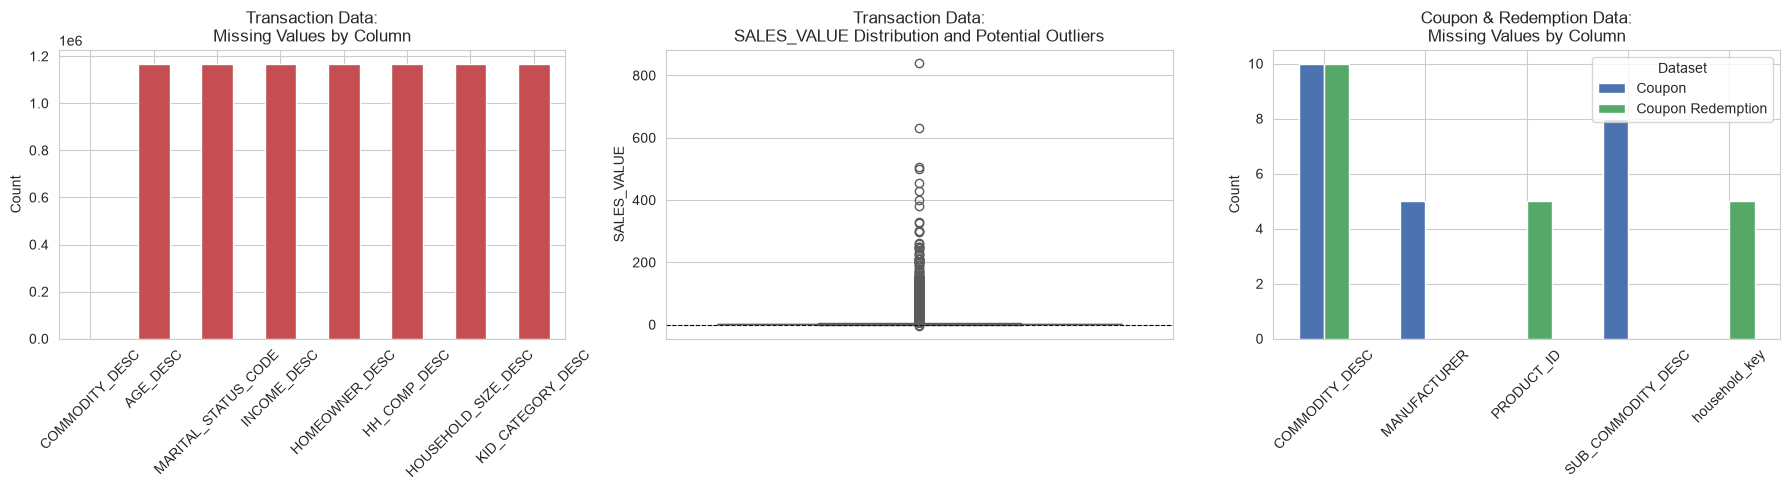

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# TRANSACTION TABLE: Missing values

missing_transaction = messy_transaction_df.isnull().sum()
missing_transaction = missing_transaction[missing_transaction > 0]

missing_transaction.plot(
    kind="bar",
    ax=axes[0],
    color="#C44E52"
)

axes[0].set_title("Transaction Data:\nMissing Values by Column")
axes[0].set_ylabel("Count")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)

# TRANSACTION TABLE: SALES_VALUE outliers

sns.boxplot(
    y=messy_transaction_df["SALES_VALUE"],
    ax=axes[1],
    color="#DD8452"
)

axes[1].set_title(
    "Transaction Data:\nSALES_VALUE Distribution and Potential Outliers"
)

axes[1].set_ylabel("SALES_VALUE")

# Reference line showing the boundary between
# positive and negative sales values
axes[1].axhline(
    0,
    color="black",
    linewidth=0.8,
    linestyle="--"
)
# COUPON + REDEMPTION TABLES: Missing values

missing_coupon = messy_coupon_df.isnull().sum()
missing_coupon = missing_coupon[missing_coupon > 0]

missing_redemption = messy_redemption_df.isnull().sum()
missing_redemption = missing_redemption[
    missing_redemption > 0
]

combined_missing = pd.DataFrame({
    "Coupon": missing_coupon,
    "Coupon Redemption": missing_redemption
}).fillna(0)

combined_missing.plot(
    kind="bar",
    ax=axes[2],
    color=["#4C72B0", "#55A868"]
)

axes[2].set_title(
    "Coupon & Redemption Data:\nMissing Values by Column"
)

axes[2].set_ylabel("Count")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=45)
axes[2].legend(title="Dataset")


plt.tight_layout()
plt.show()

end of week 1 lecture. 

#### STATISTICAL ANALYSIS


In [22]:
transaction_data = df_transaction.copy()
coupon_data = df_coupon.copy()
redemption_data = df_coupon_redemption.copy()

print("Datasets prepared for statistical analysis:")
print(f"Transactions:       {transaction_data.shape}")
print(f"Coupons:            {coupon_data.shape}")
print(f"Coupon redemptions: {redemption_data.shape}")

Datasets prepared for statistical analysis:
Transactions:       (2595732, 25)
Coupons:            (124548, 9)
Coupon redemptions: (2318441, 11)


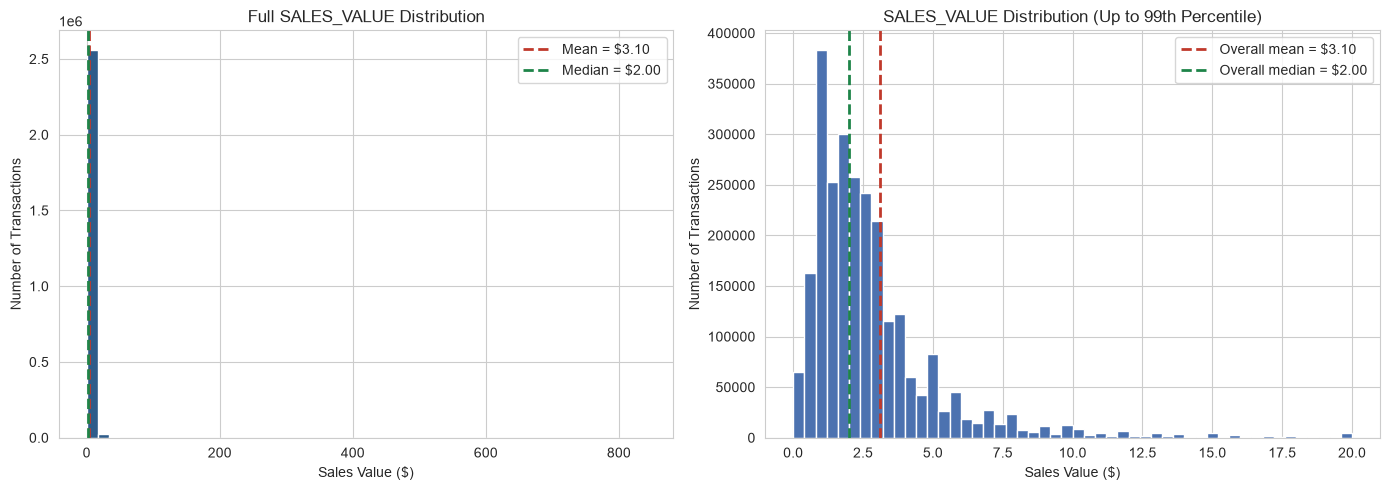

In [24]:
sales_raw = transaction_data["SALES_VALUE"].dropna()

mean_sales = sales_raw.mean()
median_sales = sales_raw.median()

# 99th percentile used only for the zoomed visualization
p99_sales = sales_raw.quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    sales_raw,
    bins=50,
    color="#2E5C8A",
    edgecolor="white"
)

axes[0].axvline(
    mean_sales,
    color="#C0392B",
    linestyle="--",
    linewidth=2,
    label=f"Mean = ${mean_sales:,.2f}"
)

axes[0].axvline(
    median_sales,
    color="#1E8449",
    linestyle="--",
    linewidth=2,
    label=f"Median = ${median_sales:,.2f}"
)

axes[0].set_title("Full SALES_VALUE Distribution")
axes[0].set_xlabel("Sales Value ($)")
axes[0].set_ylabel("Number of Transactions")
axes[0].legend()


# ------------------------------------------------------------
# 2. Zoomed distribution
# ------------------------------------------------------------

axes[1].hist(
    sales_raw[sales_raw <= p99_sales],
    bins=50,
    color="#4C72B0",
    edgecolor="white"
)

axes[1].axvline(
    mean_sales,
    color="#C0392B",
    linestyle="--",
    linewidth=2,
    label=f"Overall mean = ${mean_sales:,.2f}"
)

axes[1].axvline(
    median_sales,
    color="#1E8449",
    linestyle="--",
    linewidth=2,
    label=f"Overall median = ${median_sales:,.2f}"
)

axes[1].set_title("SALES_VALUE Distribution (Up to 99th Percentile)")
axes[1].set_xlabel("Sales Value ($)")
axes[1].set_ylabel("Number of Transactions")
axes[1].legend()


plt.tight_layout()
plt.show()

note:

should we keep only the right graph since the whole distribution can be seen properly?